# Data Exploration

This notebook explores and prepares the NIH Chest X-ray dataset for model training. We will inspect the dataset structure, verify labels and patient-level data splits, examine image dimensions and formats, and visualise sample X-rays.

The goal is to understand the data before developing a CNN model from scratch and fine-tuning a pretrained ResNet18, and finally evaluate and compare both models. 

## 01. Imports

In [1]:
# Standard library
import random
import platform
from pathlib import Path

# Data handling and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Deep learning
import torch
import torchvision
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Encourage deterministic operations where supported
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print("Random seed:", SEED)
print("Python version:", platform.python_version())
print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Pillow version:", Image.__version__)
print("\nHardware availability")
print("CUDA available:", torch.cuda.is_available())
print("Apple MPS available:", torch.backends.mps.is_available())

Random seed: 42
Python version: 3.14.3
PyTorch version: 2.15.0
Torchvision version: 0.29.2
Pandas version: 3.1.0
NumPy version: 2.5.4
Pillow version: 13.0.0

Hardware availability
CUDA available: False
Apple MPS available: True


## 02. Define project paths

Notebook will find project relative to its working directory, on any computer without relying on my personal paths.

In [2]:
# Locate project directory without relying on relative paths
cwd = Path.cwd().resolve()

PROJECT_DIR = next((path for path in [cwd, *cwd.parents]
                    if path.name == "transfer-learning-resnet"
                    and (path.parent / "data" / "processed" / "mlp_dataset.csv").exists()), 
                    None)
if PROJECT_DIR is None:
    raise FileNotFoundError("Could not locate the project directory." "Please run this notebook from inside transfer-learning-resnet.")                    

DATA_DIR = PROJECT_DIR.parent / "data"
IMAGE_DIR = DATA_DIR / "raw" / "images"
CSV_PATH = DATA_DIR / "processed" / "mlp_dataset.csv"

print("Project directory", PROJECT_DIR)
print("Data directory", DATA_DIR)
print("Image directory", IMAGE_DIR)
print("CSV path", CSV_PATH)

# Confirm required data exists
assert IMAGE_DIR.exists(), f"Image directory {IMAGE_DIR} not found."
assert CSV_PATH.exists(), f"CSV file {CSV_PATH} not found."
print("\nAll required paths verified.")

Project directory /Users/hweeenheah/Downloads/EDA_Resources/nih-chestxray-ml/transfer-learning-resnet
Data directory /Users/hweeenheah/Downloads/EDA_Resources/nih-chestxray-ml/data
Image directory /Users/hweeenheah/Downloads/EDA_Resources/nih-chestxray-ml/data/raw/images
CSV path /Users/hweeenheah/Downloads/EDA_Resources/nih-chestxray-ml/data/processed/mlp_dataset.csv

All required paths verified.


## 03. Load and inspect dataset

This experiment uses a curated subset of the NIH Chest X-ray dataset. The binary classification task is to distinguish Effusion-positive images from No Finding images. Images with Effusion alongside other findings are included as positive cases; images with other findings but no Effusion are excluded. The existing patient-level train, validation and test splits are retained to maintain consistency with earlier experiments.

In [7]:
# Load existing curated dataset (mlp_dataset.csv)
df = pd.read_csv(CSV_PATH)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
print("First five rows:\n", df.head())
print("Split distribution:")
display(pd.crosstab(df["Split"], df["Label"]))
print("Total images:", len(df))
print("Unique patients:", df["Patient ID"].nunique())

Dataset shape: (3241, 4)
Columns: ['Image Index', 'Patient ID', 'Label', 'Split']
First five rows:
         Image Index  Patient ID  Label  Split
0  00000002_000.png           2      0  train
1  00000005_000.png           5      0  train
2  00000005_001.png           5      0  train
3  00000005_002.png           5      0  train
4  00000005_003.png           5      0  train
Split distribution:


Label,0,1
Split,,
test,329,150
train,1939,269
val,486,68


Total images: 3241
Unique patients: 1127


## 04. Verify image availability and dimensions

In [9]:
# Inspect a reproducible random sample of images
sample_names = (df["Image Index"].sample(n=min(10, len(df)), random_state=SEED))
image_info = []
for image_name in sample_names:
    image_path = IMAGE_DIR / image_name
    if not image_path.exists():
        raise FileNotFoundError(f"Image file {image_path} not found.")
    with Image.open(image_path) as img:
        image_info.append({
            "Image Index": image_name,
            "Width": img.width,
            "Height": img.height,
            "Mode": img.mode,
            "Format": img.format})

image_info_df = pd.DataFrame(image_info)

display(image_info_df)
print("Image dimensions (Width x Height):\n", image_info_df[["Width", "Height"]].describe())
print("Image modes:\n", image_info_df["Mode"].value_counts())
    

,Image Index,Width,Height,Mode,Format
0,00000425_001.png,1024,1024,L,PNG
1,00000798_010.png,1024,1024,L,PNG
2,00000781_000.png,1024,1024,L,PNG
3,00000205_000.png,1024,1024,L,PNG
4,00000149_000.png,1024,1024,L,PNG
5,00000654_000.png,1024,1024,L,PNG
6,00000821_001.png,1024,1024,L,PNG
7,00000761_005.png,1024,1024,L,PNG
8,00000814_003.png,1024,1024,L,PNG
9,00001311_000.png,1024,1024,L,PNG


Image dimensions (Width x Height):
         Width  Height
count    10.0    10.0
mean   1024.0  1024.0
std       0.0     0.0
min    1024.0  1024.0
25%    1024.0  1024.0
50%    1024.0  1024.0
75%    1024.0  1024.0
max    1024.0  1024.0
Image modes:
 Mode
L    10
Name: count, dtype: int64


## 05. Visualise sample images

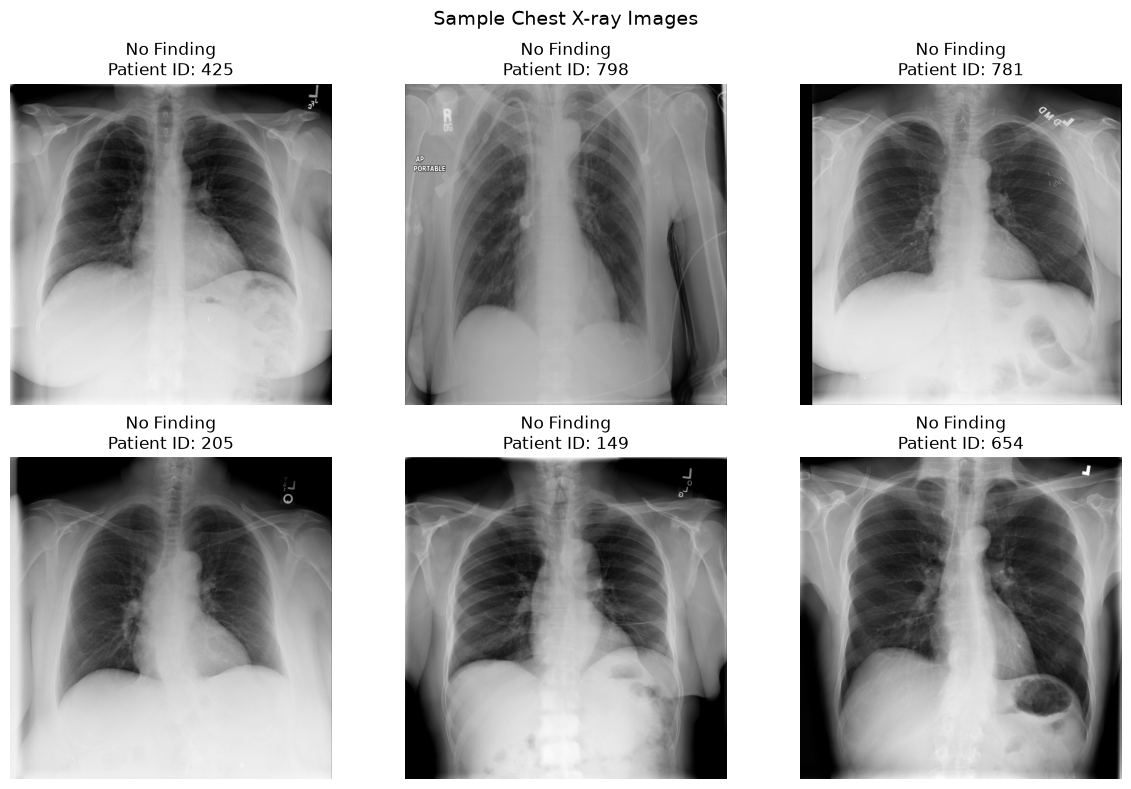

In [10]:
# Select 6 reproducible examples
sample = (df.sample(n=min(6, len(df)), random_state=SEED).reset_index(drop=True))
fig, axes = plt.subplots(2, 3, figsize=(12,8))

for ax, (_, row) in zip(axes.flat, sample.iterrows()):
    image_path = IMAGE_DIR / row["Image Index"]
    with Image.open(image_path) as img:
        ax.imshow(img.convert("L"), cmap="gray")
    label = "Effusion" if row["Label"] == 1 else "No Finding"
    ax.set_title(f"{label}\nPatient ID: {row['Patient ID']}")
    ax.axis("off")

plt.suptitle("Sample Chest X-ray Images", fontsize=14)
plt.tight_layout()
plt.show()

## 06. View Position information

In [13]:
# Load original NIH metadata
METADATA_PATH = DATA_DIR / "raw" / "Data_Entry_2017_v2020.csv"
metadata = pd.read_csv(METADATA_PATH)
print("Original metadata shape:", metadata.shape)

# Keep only relevent information
view_metadata = metadata[["Image Index", "View Position"]]

# Join view position to curated dataset
df_views = df.merge(
    view_metadata,
    on="Image Index",
    how="left",
    validate="one_to_one")
print("View position distribution:")
display(df_views["View Position"].value_counts(dropna=False))
print("View position by split:")
display(pd.crosstab(df_views["Split"], df_views["View Position"], margins=True))


Original metadata shape: (112120, 11)
View position distribution:


View Position
PA    2231
AP    1010
Name: count, dtype: int64

View position by split:


View Position,AP,PA,All
Split,,,
test,289,190,479
train,572,1636,2208
val,149,405,554
All,1010,2231,3241


## 07. Examine class distribution by view position

Is Effusion distributed differently across AP and PA?

In [14]:
# Count iamges by split, view position and label
view_label_counts = pd.crosstab(
    [df_views["Split"], df_views["View Position"]], df_views["Label"],
    margins=False)
print("Image counts by split, view position and label:")
display(view_label_counts)

# Calculate Effusion prevalence within each view and split
view_label_prevalence = (df_views
                            .groupby(["Split", "View Position"])["Label"]
                            .agg(Total_Images="count",
                                 Effusion_Images="sum",
                                 Effusion_Prevalence="mean"))
print("Effusion prevalence by split and view position:")
display(view_label_prevalence)

Image counts by split, view position and label:


Label                   0    1
Split View Position           
test  AP              200   89
      PA              129   61
train AP              471  101
      PA             1468  168
val   AP              106   43
      PA              380   25

Effusion prevalence by split and view position:


Total_Images  Effusion_Images  Effusion_Prevalence
Split View Position                                                    
test  AP                      289               89             0.307958
      PA                      190               61             0.321053
train AP                      572              101             0.176573
      PA                     1636              168             0.102689
val   AP                      149               43             0.288591
      PA                      405               25             0.061728

### Dataset distribution observations

The curated dataset contains 3241 frontal chest X-ray images (2208 training, 554 validation and 479 test images), comprising both AP and PA projections.

The distribution of Effusion-positive cases differs across the three splits. In particular, Effusion prevalence in the test set is approximately 31.3%, compared to 12.2% in the training set and 12.3% in the validation set.

This difference indicates that the test set is not identically distributed to the training and validation sets with respect to class prevalence and view position. Consequently, evaluation metrics such as average precision and precision may be affected by this distribution shift.

The original patient-level splits are retained to preserve consistency with previous experiments. Results will be interpreted and compared with these limitations in mind.

## 08. Images per patient

It is established that there are no patient overlap between splits. However, patients can contribute multiple images within the same split. 

In [17]:
# Count images contributed by each patient in each split
patient_image_counts = (df_views
                        .groupby(["Split", "Patient ID"])
                        .size()
                        .reset_index(name="Image_Count"))
print("Images per patient, by split:")
display(patient_image_counts
        .groupby("Split")["Image_Count"]
        .describe()
        .round(2))

# Check number of patients contributing multiple images
print("Patient with multiple images:")
display(patient_image_counts
        .assign(Multiple_Images=lambda x: x["Image_Count"] > 1)
        .groupby("Split")["Multiple_Images"]
        .agg(["sum", "count"]))        

Images per patient, by split:


,count,mean,std,min,25%,50%,75%,max
Split,,,,,,,,
test,52.0,9.21,10.02,1.0,2.75,4.0,10.5,36.0
train,868.0,2.54,2.98,1.0,1.00,1.0,3.0,32.0
val,207.0,2.68,3.87,1.0,1.00,1.0,2.5,33.0


Patient with multiple images:


,sum,count
Split,,
test,47,52
train,393,868
val,89,207


### Patient-level distribution

The 3241 images represent 1127 unique patients. It was previously verified to have 0 patient overlap between the training, validation and test sets.

However, the number of images contributed by each patient differs across different splits. The test set contains 479 images from only 52 patients, with a median of 4 images per patient. In comparison, the training and validation sets have median values of 1 image per patient.

This means that the test observations are clustered within a relatively small number of patients and should not be interpreted as 479 fully independent observations. Test performance may therefore be sensitive to patient-level variation.

The existing patient-level splits are retained, and this limitation will be considered when interpreting model performance.

## Summary and Key Considerations

This project uses a curated subset of 3241 frontal chest X-ray images from 1127 unique patients to classify Effusion-positive images against No Finding images.

Key observations:
*Image characteristics:* All images are 1024x1024 grayscale images comprising AP and PA projections
*Class imbalance:* Effusion-positive images represent approximately 12.2% of the training set.
*Distribution differences:* The test set has a higher Effusion prevalence (31.3%) and a different AP/PA composition compared with training and validation.
*Patient distribution:* Although there is no patient overlap between splits, the 479 test images represent only 52 unique patients, with multiple images contributed by many patients.

The original patient-level splits and dataset composition will be retained for this experiment to ensure compatibility and comparability to previous experiments. These observations will be considered when interpreting model perofrmance and its generalisability.